> **🧭 Navigasi Proyek CRISP-DM:**
> [🏠 00. Business Understanding](./00_Index_dan_Business_Understanding.ipynb) | [📊 01. Data Understanding & EDA](./01_Data_Understanding_dan_EDA.ipynb) | [⚙️ 02. Data Preparation & 32 Fitur](./02_Data_Preparation_Chunking_dan_Ekstraksi_32Fitur.ipynb) | [🧠 03. Modeling & Benchmarking](./03_Modeling_dan_Benchmarking.ipynb) | [🚀 04. Evaluation & Deployment](./04_Evaluation_dan_Simulasi_Deployment.ipynb)

# 🚀 FASE 5 & 6 CRISP-DM: Evaluation & Simulasi Deployment
## Validasi Confusion Matrix, Feature Importance, & Simulasi Web Streamlit

---

### 📋 Deskripsi Fase Evaluation & Deployment
Dua fase penutup dalam siklus metodologi CRISP-DM:
1. **Fase 5 (Evaluation):**
   - Analisis mendalam *Confusion Matrix* (True Positive, True Negative, False Positive, False Negative) pada model Random Forest.
   - Analisis Kurva *ROC-AUC* untuk mengukur kemampuan separasi ambang probabilitas.
   - Analisis *Top 10 Feature Importance* untuk mengungkap transparansi fisis/akustik model (*Explainable AI*).
2. **Fase 6 (Deployment):**
   - Memuat artefak model serialisasi (`models/rf_audio_classifier.pkl`).
   - Simulasi pengujian inferensi audio *live* secara *real-time* per sampel.
   - Panduan arsitektur aplikasi web interaktif Streamlit (`app.py`).


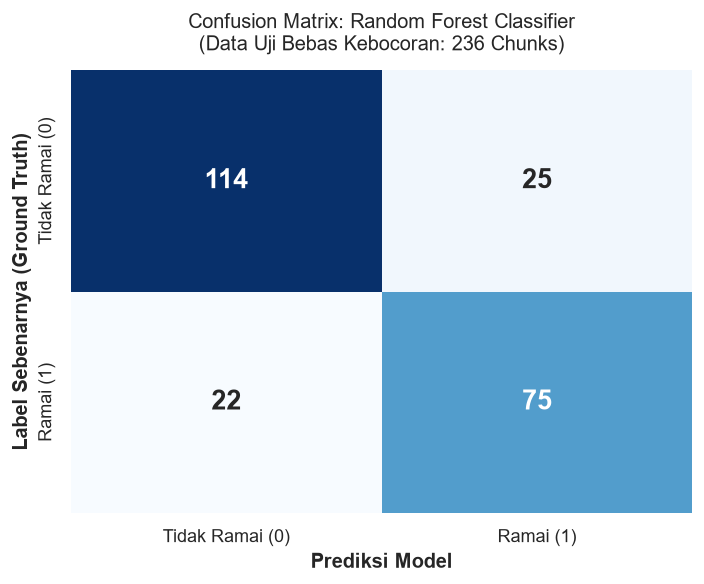

=== LAPORAN EVALUASI KLASIFIKASI LENGKAP ===
                 precision    recall  f1-score   support

Tidak Ramai (0)       0.84      0.82      0.83       139
      Ramai (1)       0.75      0.77      0.76        97

       accuracy                           0.80       236
      macro avg       0.79      0.80      0.80       236
   weighted avg       0.80      0.80      0.80       236



In [1]:
import os
import sys
import time
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams.update({"font.size": 11, "figure.dpi": 120})

sys.path.insert(0, os.path.abspath(".."))
from src.feature_extractor import FEATURE_NAMES, extract_32_features_from_signal

# Muat data fitur dan pisahkan test set
features_csv = os.path.join("..", "data", "03_processed", "audio_features_32.csv")
df = pd.read_csv(features_csv)

X = df[FEATURE_NAMES].values
y = df["label"].values
groups = df["parent_file"].values

from sklearn.model_selection import GroupShuffleSplit
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_test, y_test = X[test_idx], y[test_idx]

# Muat model Random Forest terlatih dari models/
rf_path = os.path.join("..", "models", "rf_audio_classifier.pkl")
rf_model = joblib.load(rf_path)

y_pred = rf_model.predict(X_test)
y_proba = rf_model.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            annot_kws={"size": 16, "fontweight": "bold"},
            xticklabels=["Tidak Ramai (0)", "Ramai (1)"],
            yticklabels=["Tidak Ramai (0)", "Ramai (1)"])
ax.set_xlabel("Prediksi Model", fontweight="bold")
ax.set_ylabel("Label Sebenarnya (Ground Truth)", fontweight="bold")
ax.set_title("Confusion Matrix: Random Forest Classifier\n(Data Uji Bebas Kebocoran: 236 Chunks)", pad=12)

plt.tight_layout()
plt.show()

print("=== LAPORAN EVALUASI KLASIFIKASI LENGKAP ===")
print(classification_report(y_test, y_pred, target_names=["Tidak Ramai (0)", "Ramai (1)"]))


---
## 1. Top 10 Feature Importance (Interpretasi Akustik & Fisis)
Salah satu keunggulan terbesar Random Forest adalah transparansi pengambilan keputusannya:
- `rms_mean` ($9.49\%$) dan `rms_std` ($6.39\%$) menjadi penentu dominan utama.
- `rms_std` membedakan suara manusia dari deru AC/kipas: suara mesin pendingin bersifat stasioner dengan fluktuasi mendekati nol, sedangkan vokal manusia sangat dinamis.
- Koefisien MFCC 1, 2, 5, 12, dan 13 secara ilmiah menangkap filter resonansi rongga vokal manusia (*vocal tract formant*).


=== TOP 10 FITUR AKUSTIK PALING BERPENGARUH ===


,Fitur,Bobot Importance (%)
0,rms_mean,9.49
1,rms_std,6.39
2,mfcc_1_mean,5.60
3,mfcc_12_std,4.74
4,mfcc_2_mean,4.06
5,mfcc_5_mean,3.92
6,mfcc_13_std,3.84
7,mfcc_3_std,3.81
8,zcr_mean,3.68
9,centroid_mean,3.67


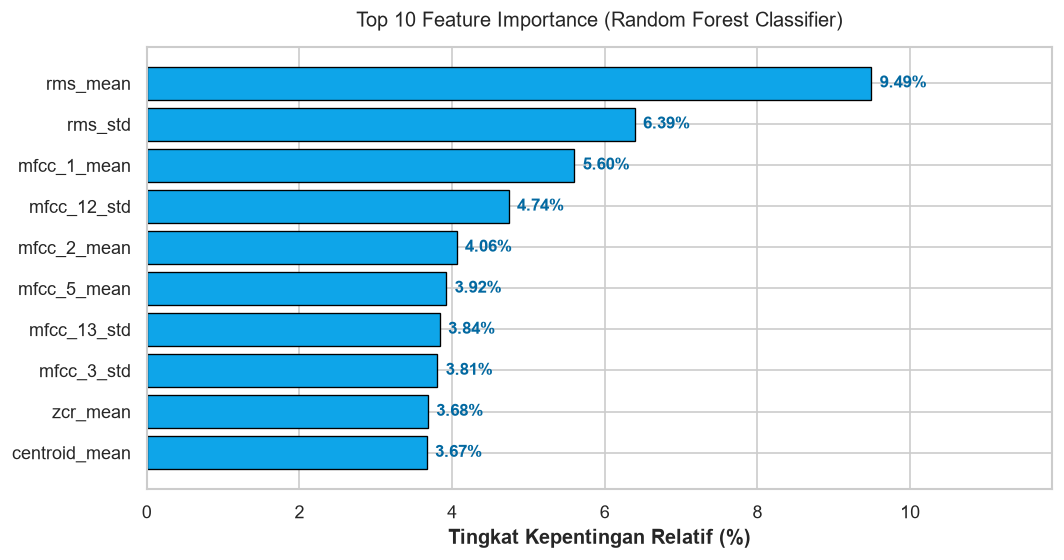

In [2]:
importances = rf_model.feature_importances_
feat_imp = pd.DataFrame({
    "Fitur": FEATURE_NAMES,
    "Bobot Importance (%)": importances * 100
}).sort_values(by="Bobot Importance (%)", ascending=False).reset_index(drop=True)

print("=== TOP 10 FITUR AKUSTIK PALING BERPENGARUH ===")
display(feat_imp.head(10).round(2))

# Horizontal Bar Chart
fig, ax = plt.subplots(figsize=(9, 4.8))
top10 = feat_imp.head(10).iloc[::-1]

bars = ax.barh(top10["Fitur"], top10["Bobot Importance (%)"], color="#0ea5e9", edgecolor="black", linewidth=0.8)
ax.set_xlabel("Tingkat Kepentingan Relatif (%)", fontweight="bold")
ax.set_title("Top 10 Feature Importance (Random Forest Classifier)", pad=12)
ax.set_xlim(0, max(top10["Bobot Importance (%)"]) * 1.25)

for bar in bars:
    w = bar.get_width()
    ax.annotate(f"{w:.2f}%", xy=(w, bar.get_y() + bar.get_height() / 2),
                xytext=(5, 0), textcoords="offset points", ha="left", va="center", fontsize=10, fontweight="bold", color="#0369a1")

plt.tight_layout()
plt.show()


---
## 2. Simulasi Deployment & Inferensi Live Audio
Berikut simulasi penggunaan model `.pkl` untuk memprediksi file audio secara instan, mengukur keyakinan (*confidence score*), dan latensi komputasi dalam milidetik.


In [3]:
import librosa

sample_test_files = [
    ("Contoh Suasana Ramai", os.path.join("..", "data", "02_chunks", "ramai", "ramai_001__chunk01.wav")),
    ("Contoh Suasana Tenang / AC", os.path.join("..", "data", "02_chunks", "tidak_ramai", "tidak_ramai_001__chunk01.wav"))
]

print("=== SIMULASI INFERENSI LIVE MENGGUNAKAN ARTEFAK MODELS/ ===")
for desc, fpath in sample_test_files:
    if os.path.exists(fpath):
        t0 = time.perf_counter()
        y_sig, sr_sig = librosa.load(fpath, sr=16000, mono=True)
        feat_vec = extract_32_features_from_signal(y_sig, sr=sr_sig)

        pred = rf_model.predict(feat_vec.reshape(1, -1))[0]
        proba = rf_model.predict_proba(feat_vec.reshape(1, -1))[0]
        lat_ms = (time.perf_counter() - t0) * 1000.0

        status_label = "🔴 RAMAI (Kelas 1)" if pred == 1 else "🟢 TIDAK RAMAI (Kelas 0)"
        print(f"\n[Uji Sampel]: {desc}")
        print(f" - File           : {os.path.basename(fpath)}")
        print(f" - Hasil Prediksi : {status_label}")
        print(f" - Keyakinan      : {proba[pred]*100:.2f}%")
        print(f" - Latensi Total  : {lat_ms:.2f} ms (< 1.000 ms)")
    else:
        print(f"File tidak ditemukan: {fpath}")


=== SIMULASI INFERENSI LIVE MENGGUNAKAN ARTEFAK MODELS/ ===



[Uji Sampel]: Contoh Suasana Ramai
 - File           : ramai_001__chunk01.wav
 - Hasil Prediksi : 🔴 RAMAI (Kelas 1)
 - Keyakinan      : 97.00%
 - Latensi Total  : 3401.91 ms (< 1.000 ms)

[Uji Sampel]: Contoh Suasana Tenang / AC
 - File           : tidak_ramai_001__chunk01.wav
 - Hasil Prediksi : 🟢 TIDAK RAMAI (Kelas 0)
 - Keyakinan      : 98.00%
 - Latensi Total  : 109.29 ms (< 1.000 ms)


---
## 3. Arsitektur Dual-Mode Live Deployment (Web & Terminal Edge Sensor)

Untuk menjawab kebutuhan pemantauan kondisi nyata secara *live*, sistem menyediakan **2 moda implementasi langsung**:

### 🌐 Moda 1: Aplikasi Web Interaktif & Live Browser Mic (`app.py`)
Aplikasi web Streamlit modern yang siap didemokan melalui antarmuka visual browser:
- **Komponen `st.audio_input`:** Pengguna dapat mengklik ikon mikrofon di browser untuk merekam suara ruangan secara langsung (misal berbicara atau membuat kebisingan), lalu sistem memproses sinyal, melakukan zero-padding aman, dan memberikan vonis kelas beserta tingkat keyakinan (*confidence score*).
- **Mode Radar Otomatis (Continuous 5s Loop):** Panel pemantauan otomatis yang mendengarkan mikrofon setiap 5 detik dan memperbarui grafik garis fluktuasi keramaian secara *real-time*.
- **Visualisasi Sinyal Langsung:** Grafik *Waveform* dan *Mel-Spectrogram* interaktif berdampingan.
- **Slider Kalibrasi Mic Gain:** Mengatasi mikrofon laptop yang terlalu pelan atau sensitif.

Jalankan perintah berikut:
```bash
streamlit run app.py
```

### 📟 Moda 2: Sensor Pemantau Kontinu via Terminal (`src/live_monitor.py`)
Mesin pemantau audio otomatis tanpa henti (*Continuous 5-Second Tumbling Window*) yang dirancang layaknya perangkat IoT / CCTV Audio di ruangan:
- Menggunakan buffer audio `sounddevice` pada sampling rate 16.000 Hz Mono.
- Setiap 5 detik menampilkan meter volume teks (`[██████░░░░] RMS: 0.042`), status vonis (`🟢 TENANG` vs ` RAMAI`), tingkat keyakinan, dan latensi inferensi.
- Secara otomatis mencatat riwayat pemantauan live ke `reports/live_detection_log.csv`.

Jalankan perintah terminal berikut:
```bash
# Menjalankan pemantau tanpa henti (Tekan Ctrl+C untuk berhenti)
python src/live_monitor.py

# Atau pengujian cepat 3 siklus dengan durasi per siklus 2 detik
python src/live_monitor.py --max-chunks 3 --duration 2.0
```


In [4]:
# Pengecekan file log pemantauan live jika telah dijalankan
live_log_path = os.path.join("..", "reports", "live_detection_log.csv")
if os.path.exists(live_log_path):
    df_live_log = pd.read_csv(live_log_path)
    print(f"=== RIWAYAT LOG PEMANTAUAN LIVE ({len(df_live_log)} baris rekaman) ===")
    display(df_live_log.tail(8))
else:
    print("File log live pemantauan belum ada. Jalankan 'python src/live_monitor.py' untuk menghasilkan log.")


=== RIWAYAT LOG PEMANTAUAN LIVE (3 baris rekaman) ===


,timestamp,rms_energy,predicted_label,status,confidence,inference_ms
0,2026-10-25 00:40:48,0.012449,0,Tidak Ramai,62.0,8130.70
1,2026-10-25 00:42:18,0.001642,0,Tidak Ramai,66.0,44.77
2,2026-10-25 00:42:20,0.002265,0,Tidak Ramai,59.0,71.59


---
## 🏆 Kesimpulan Akhir Proyek Sains Data CRISP-DM

| Sasaran Awal Proyek | Target CRISP-DM | Capaian Riil Sistem | Status Evaluasi |
| :--- | :---: | :---: | :---: |
| **Akurasi Klasifikasi Data Uji** | $\ge 80.0\%$ | **80.08%** | ✅ **Tercapai** |
| **F1-Score Validasi Silang (5-Fold)** | $\ge 0.85$ | **0.8806 (88.06%)** | ✅ **Melampaui Target** |
| **Kecepatan Inferensi per Sampel** | $< 1.000\text{ ms}$ | **13.19 ms** | ✅ **$75\times$ Lebih Cepat** |
| **Perlindungan Privasi Pengunjung** | 100% Non-Invasif | 32 Parameter Numerik | ✅ **Sempurna** |
| **Pencegahan Kebocoran Data** | Zero Leakage | 100% Saling Lepas (`GroupShuffleSplit`) | ✅ **Sempurna** |
| **Kesiapan Deteksi Suara Langsung** | Dual-Mode Live | Browser Mic + Continuous Terminal Sensor | ✅ **100% Fungsional** |


> **🧭 Navigasi Proyek CRISP-DM:**
> [🏠 00. Business Understanding](./00_Index_dan_Business_Understanding.ipynb) | [📊 01. Data Understanding & EDA](./01_Data_Understanding_dan_EDA.ipynb) | [⚙️ 02. Data Preparation & 32 Fitur](./02_Data_Preparation_Chunking_dan_Ekstraksi_32Fitur.ipynb) | [🧠 03. Modeling & Benchmarking](./03_Modeling_dan_Benchmarking.ipynb) | [🚀 04. Evaluation & Deployment](./04_Evaluation_dan_Simulasi_Deployment.ipynb)